1. DATA INGESTION

In [ ]:
import pandas as pd
import numpy as np

# OPSI A (DEFAULT): Membaca file yang sudah di-upload di panel Colab
df = pd.read_csv('water_potability.csv')

# OPSI B (BACKUP): Load via GitHub Sir Zirzaa (Jika file belum/gagal di-upload)
# github_url = "aku-sembunyikan"
# df = pd.read_csv(github_url)

# EKSPLORASI AWAL DATASET

print("=== 5 DATA TERATAS ===")
display(df.head())

print("\n=== STRUKTUR DATASET & MISSING VALUES ===")
df.info()

=== 5 DATA TERATAS ===


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0



=== STRUKTUR DATASET & MISSING VALUES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


2. DATA PREPROCESSING

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 1. Memisahkan Fitur (X) dan Target/Label (y)
X = df.drop(columns=['Potability'])
y = df['Potability']

# 2. Split Data (80% Data Latih, 20% Data Uji)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Handling Missing Values (Imputasi Nilai Median)
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# 4. Feature Scaling (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("✅ Preprocessing Selesai!")
print(f"Jumlah Data Latih (Train): {X_train_scaled.shape[0]} sampel")
print(f"Jumlah Data Uji (Test)  : {X_test_scaled.shape[0]} sampel")

✅ Preprocessing Selesai!
Jumlah Data Latih (Train): 2620 sampel
Jumlah Data Uji (Test)  : 656 sampel


3. MODEL TRAINING

In [ ]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Inisialisasi Algoritma dengan Configuration Clear
model = RandomForestClassifier(
    n_estimators=100,    # Jumlah pohon keputusan (100 Decision Trees)
    random_state=42,     # Mengunci acakan agar hasil konsisten
    n_jobs=-1            # Memakai seluruh core CPU Colab agar cepat
)

# 2. Proses Pelatihan & Mengukur Waktu Komputasi
start_time = time.time()
print("\n⏳ Sedang melatih 100 pohon keputusan pada data latih...")

model.fit(X_train_scaled, y_train)

end_time = time.time()
execution_time = end_time - start_time

# 3. Evaluasi Singkat pada Data Latih (Train Set)
y_train_pred = model.predict(X_train_scaled)
train_acc = accuracy_score(y_train, y_train_pred)

# 4. Output Ringkasan Hasil Training
print("✅ Pelatihan Model Selesai!\n")
print(f"⏱️  Waktu Pelatihan : {execution_time:.2f} detik")
print(f"🌳 Total Decision Trees : {model.n_estimators} pohon")
print(f"🎯 Akurasi Data Latih   : {train_acc * 100:.2f}%")
print("=" * 60)


⏳ Sedang melatih 100 pohon keputusan pada data latih...
✅ Pelatihan Model Selesai!

⏱️  Waktu Pelatihan : 1.31 detik
🌳 Total Decision Trees : 100 pohon
🎯 Akurasi Data Latih   : 100.00%


4. MODEL EVALUATION

📊 Akurasi Model: 66.31%

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Tidak Layak (0)       0.67      0.89      0.76       400
Layak Minum (1)       0.64      0.30      0.41       256

       accuracy                           0.66       656
      macro avg       0.66      0.60      0.59       656
   weighted avg       0.66      0.66      0.63       656



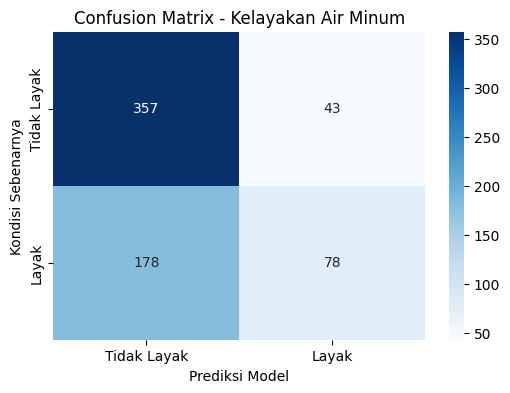

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Prediksi Data Uji (Test Set)
y_pred = model.predict(X_test_scaled)

# 2. Hitung Akurasi
acc = accuracy_score(y_test, y_pred)
print(f"📊 Akurasi Model: {acc * 100:.2f}%\n")

# 3. Laporan Klasifikasi Lengkap
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Tidak Layak (0)', 'Layak Minum (1)']))

# 4. Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak Layak', 'Layak'], yticklabels=['Tidak Layak', 'Layak'])
plt.xlabel('Prediksi Model')
plt.ylabel('Kondisi Sebenarnya')
plt.title('Confusion Matrix - Kelayakan Air Minum')
plt.show()